# Trends: vehicle stops and collisions by month

**A1.** How have vehicle stops and collisions changed over time, and do they move together month by month?

**Inputs:** `data/processed/vehicle_stops.csv`, `data/processed/collisions.csv`

**Outputs:** `figures/02_a1_monthly_trends.png`, `figures/02_a1_stops_vs_collisions.png`, `results/02_a1_monthly_counts.csv`, `results/02_a1_yearly_totals.csv`, `results/02_a1_correlation.csv`

In [1]:
# Shared loaders, the monthly counter, plot style, and project settings
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from bpdtools.config import ANALYSIS_END
from bpdtools.paths import repo_path
from bpdtools.plots import PALETTE, set_plot_style
from bpdtools.traffic import load_collisions, load_stops
from bpdtools.trends import monthly_counts

set_plot_style()

# Figures and result tables go to fixed folders at the repository root
figures = repo_path("figures")
results = repo_path("results")
figures.mkdir(exist_ok=True)
results.mkdir(exist_ok=True)

# Stop Data starts in January 2024 and the analysis window ends in
# December 2025, so both sources cover the same 24 whole months
FIRST_MONTH = pd.Period("2024-01", freq="M")
LAST_MONTH = pd.Period(ANALYSIS_END, freq="M")

# Level of the interval around each correlation
CONFIDENCE_LEVEL = 0.95

## Monthly counts

Each stop counts once by `LEA_Record_ID`. A collision without a date has no month and is left out.

In [2]:
# Count each vehicle stop once by its record id, in the month of its date
stops = load_stops()
stop_months = monthly_counts(stops, "StopDate", id_column="LEA_Record_ID")

# Collisions go back to 2007; monthly_counts skips the rows without a date
collisions = load_collisions()
collision_months = monthly_counts(collisions, "Date")

# Keep the 24 months that both sources cover
monthly = pd.DataFrame(
    {
        "vehicle_stops": stop_months.loc[FIRST_MONTH:LAST_MONTH],
        "collisions": collision_months.loc[FIRST_MONTH:LAST_MONTH],
    }
)
monthly.to_csv(results / "02_a1_monthly_counts.csv")

# Checks: the number of months, missing values, and undated collisions
checks = pd.Series(
    {
        "months": len(monthly),
        "missing values": int(monthly.isna().sum().sum()),
        "collisions without a date": int(collisions["Date"].isna().sum()),
    },
    name="value",
)
checks

months                        24
missing values                 0
collisions without a date    101
Name: value, dtype: int64

## How did the counts change?

In [3]:
# Totals of each calendar year, one row per source
first_year, last_year = FIRST_MONTH.year, LAST_MONTH.year
yearly = monthly.groupby(monthly.index.year).sum().T
yearly.index.name = "source"
yearly.columns.name = "year"

# Change from the first year to the last, in percent
yearly["change_pct"] = ((yearly[last_year] / yearly[first_year] - 1) * 100).round(1)
yearly.to_csv(results / "02_a1_yearly_totals.csv")
yearly

year,2024,2025,change_pct
source,,,
vehicle_stops,3232,3078,-4.8
collisions,877,784,-10.6


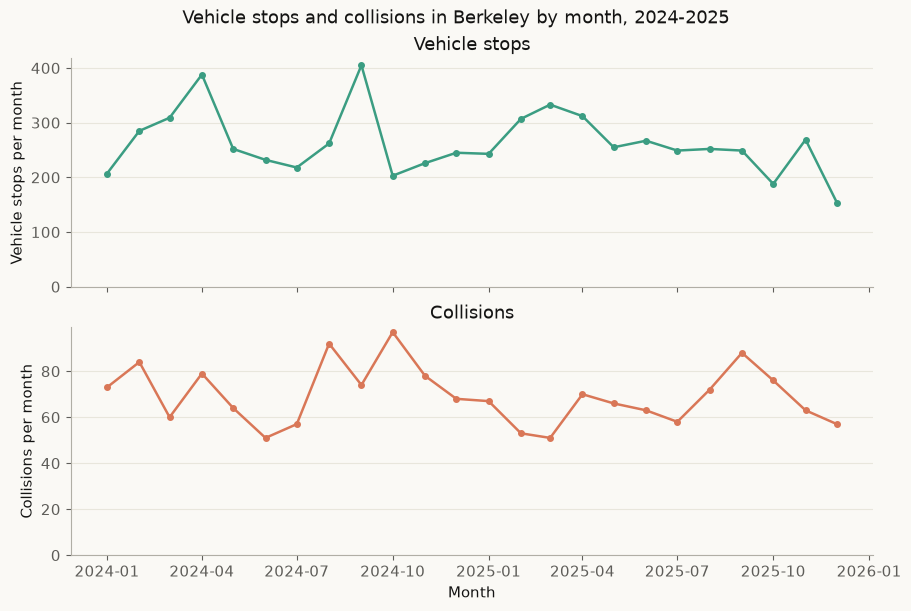

In [4]:
# One panel per source, because stops run about four times higher than
# collisions; each point is the first day of its month
month_starts = monthly.index.to_timestamp()
panels = [
    ("vehicle_stops", "Vehicle stops", PALETTE[0]),
    ("collisions", "Collisions", PALETTE[1]),
]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, (column, label, color) in zip(axes, panels):
    ax.plot(month_starts, monthly[column], marker="o", color=color)
    ax.set_title(label)
    ax.set_ylabel(f"{label} per month")
    ax.set_ylim(bottom=0)
axes[-1].set_xlabel("Month")
fig.suptitle(
    f"Vehicle stops and collisions in Berkeley by month, {first_year}-{last_year}"
)
fig.savefig(figures / "02_a1_monthly_trends.png")

A count of 0 in a month would mean no records in the dataset that month, not that no stop or collision happened. None of the 24 months is 0 here: the lowest months have 154 stops and 51 collisions.

## Do they move together?

Pearson correlation of the monthly counts, with a 95% interval. Two checks: ranks (Spearman), and month-to-month changes, which remove a slow drift that both series could share.

In [5]:
# Pearson correlation of the monthly counts and its interval (Fisher z)
levels = stats.pearsonr(monthly["vehicle_stops"], monthly["collisions"])
levels_interval = levels.confidence_interval(confidence_level=CONFIDENCE_LEVEL)

# Check with ranks, which one extreme month cannot dominate
ranks = stats.spearmanr(monthly["vehicle_stops"], monthly["collisions"])

# Check with the change from one month to the next (23 changes)
changes = monthly.diff().dropna()
steps = stats.pearsonr(changes["vehicle_stops"], changes["collisions"])
steps_interval = steps.confidence_interval(confidence_level=CONFIDENCE_LEVEL)

correlation = pd.DataFrame(
    [
        {
            "measure": "Pearson, monthly counts",
            "n": len(monthly),
            "r": levels.statistic,
            "ci_low": levels_interval.low,
            "ci_high": levels_interval.high,
            "p_value": levels.pvalue,
        },
        {
            "measure": "Spearman, monthly counts",
            "n": len(monthly),
            "r": ranks.statistic,
            "ci_low": float("nan"),
            "ci_high": float("nan"),
            "p_value": ranks.pvalue,
        },
        {
            "measure": "Pearson, month-to-month changes",
            "n": len(changes),
            "r": steps.statistic,
            "ci_low": steps_interval.low,
            "ci_high": steps_interval.high,
            "p_value": steps.pvalue,
        },
    ]
).round(3)
correlation.to_csv(results / "02_a1_correlation.csv", index=False)
correlation

,measure,n,r,ci_low,ci_high,p_value
0,"Pearson, monthly counts",24,-0.029,-0.427,0.379,0.894
1,"Spearman, monthly counts",24,-0.050,NaN,NaN,0.816
2,"Pearson, month-to-month changes",23,-0.115,-0.504,0.312,0.600


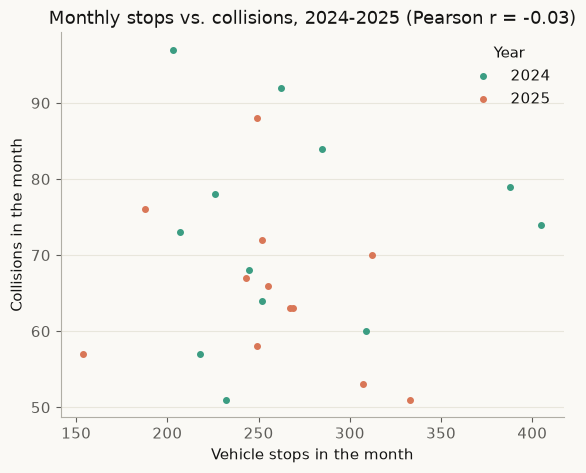

In [6]:
# Each point is one month, colored by year
fig, ax = plt.subplots(figsize=(6.5, 5))
for year, color in zip(range(first_year, last_year + 1), PALETTE):
    months_of_year = monthly.loc[monthly.index.year == year]
    ax.scatter(
        months_of_year["vehicle_stops"],
        months_of_year["collisions"],
        color=color,
        label=str(year),
    )
ax.set_xlabel("Vehicle stops in the month")
ax.set_ylabel("Collisions in the month")
ax.set_title(
    f"Monthly stops vs. collisions, {first_year}-{last_year} "
    f"(Pearson r = {levels.statistic:.2f})"
)
ax.legend(title="Year")
fig.savefig(figures / "02_a1_stops_vs_collisions.png")

## Findings

- **Both fell from 2024 to 2025.** Vehicle stops went from 3,232 to 3,078 (-4.8%), and collisions from 877 to 784 (-10.6%).
- **They did not move together month by month.** The correlation of the 24 monthly counts is r = -0.03 (95% interval -0.43 to 0.38). Ranks give -0.05, and month-to-month changes give -0.12.
- **Their busiest months differ.** Stops peaked in April and September 2024 (388 and 405), and collisions in August and October 2024 (92 and 97).

## Limitations

- 24 months is a short series, so the interval is wide: a moderate link in either direction is not ruled out. Neighboring months are not independent, which makes the interval, if anything, too narrow.
- Stop Data starts in 2024 and holds only vehicle stops.
- The 101 collisions without a date are left out. Collision times before 06:00 look unreliable, but monthly counts use only the date.
- A count of 0 would only mean no records in the dataset that month. No month here is 0, but a zero in a later snapshot should be read that way.
- Monthly totals say nothing about place. Stops and collisions could still line up by beat (see A5).